# 1D nonconforming oversampling MsFEM with parabolic correctors

We solve $-(a^\varepsilon u_\varepsilon')'=1$ on $(0,1)$ with zero Dirichlet data and
$$a^\varepsilon(x)=\frac{1}{2+\cos(2\pi x/\varepsilon)}.$$

The physical period $\varepsilon$ is independent of both meshes. We first choose the number of coarse cells $N_H$, then the number of fine cells per coarse cell $N_h=H/h$. Finally, the oversampling width is $\delta=n_\delta h$ with integer $n_\delta$, and $R=\delta/\varepsilon$. Hence all coarse-cell and patch endpoints are fine-grid nodes even when $h$ does not divide $\varepsilon$.

In [1]:
import os
os.environ["CC"] = "/usr/bin/clang"
os.environ["CXX"] = "/usr/bin/clang++"
os.environ["PATH"] = "/usr/bin:/bin:/usr/sbin:/sbin:" + os.environ["PATH"]

import itertools
import numpy as np
import matplotlib.pyplot as plt
import ufl
from mpi4py import MPI
from dolfinx import default_scalar_type, fem, mesh
from dolfinx.fem.petsc import LinearProblem
from numpy.polynomial.legendre import leggauss
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True})
_solver_counter = itertools.count()

## Mesh and oversampling parameters

The construction order is
$$H=1/N_H,\qquad h=H/N_h,\qquad \delta=n_\delta h,\qquad R=\delta/\varepsilon.$$
Here $N_h$ means fine cells per coarse cell, not the total number of fine cells. The full fine grid has $N_HN_h$ cells.

In [2]:
def mesh_sizes(NH, Nh):
    """Return H, h, and the total number of fine cells."""
    if int(NH) != NH or int(Nh) != Nh or NH <= 0 or Nh <= 0:
        raise ValueError("NH and Nh must be positive integers")
    H = 1.0 / int(NH)
    h = H / int(Nh)
    return H, h, int(NH) * int(Nh)

def oversampling_width(n_delta, h, epsilon):
    """Return delta=n_delta*h and R=delta/epsilon."""
    if int(n_delta) != n_delta or n_delta < 0:
        raise ValueError("n_delta must be a nonnegative integer")
    delta = int(n_delta) * h
    return delta, delta / epsilon

epsilon = 0.017                 # arbitrary physical period
NH = 8                          # number of coarse cells
Nh = 256                         # fine cells per coarse cell
H, h, N_fine = mesh_sizes(NH, Nh)

n_delta = int(0.125*H/h)

delta, R = oversampling_width(n_delta, h, epsilon)

MAX_DIMENSIONLESS_DT = 5.0e-3
THETA_CONSTANT = np.sqrt(3.0) / (2.0*np.pi)

print(f"epsilon={epsilon:.6g}, H={H:.6g}, h={h:.6g}")
print(f"Nh=H/h={Nh}, epsilon/h={epsilon/h:.6g}")
print(f"n_delta={n_delta}, delta={delta:.6g}, R=delta/epsilon={R:.6g}")

epsilon=0.017, H=0.125, h=0.000488281
Nh=H/h=256, epsilon/h=34.816
n_delta=32, delta=0.015625, R=delta/epsilon=0.919118


## Coefficient, periodic corrector, and patch geometry

For this coefficient the zero-mean periodic corrector in physical coordinates is
$$\chi^\varepsilon(x)=\frac{\varepsilon}{4\pi}\sin(2\pi x/\varepsilon),\qquad (\chi^\varepsilon)'(x)=\tfrac12\cos(2\pi x/\varepsilon).$$

In [3]:
def coefficient(x, epsilon):
    return 1.0 / (2.0 + np.cos(2.0*np.pi*x/epsilon))

def periodic_corrector(x, epsilon):
    return epsilon*np.sin(2.0*np.pi*x/epsilon)/(4.0*np.pi)

def periodic_corrector_derivative(x, epsilon):
    return 0.5*np.cos(2.0*np.pi*x/epsilon)

def exact_flux_constant(epsilon):
    """Constant C in a^epsilon u'=C-x, chosen so that u(1)=0."""
    wave_number = 2.0*np.pi/epsilon
    numerator = (1.0 + np.sin(wave_number)/wave_number
                 - (1.0 - np.cos(wave_number))/wave_number**2)
    denominator = 2.0 + np.sin(wave_number)/wave_number
    return numerator / denominator

def exact_solution(x, epsilon):
    """Exact solution of -(a^epsilon u')'=1 with u(0)=u(1)=0."""
    wave_number = 2.0*np.pi/epsilon
    C = exact_flux_constant(epsilon)
    return (2.0*C*x - x**2
            + (C - x)*np.sin(wave_number*x)/wave_number
            + (1.0 - np.cos(wave_number*x))/wave_number**2)

def exact_solution_derivative(x, epsilon):
    C = exact_flux_constant(epsilon)
    return (C - x)*(2.0 + np.cos(2.0*np.pi*x/epsilon))

def patch_geometry(cell, NH, h, n_delta):
    """Coarse cell K and clipped patch S_K=K enlarged by delta on both sides."""
    H = 1.0 / NH
    delta = n_delta * h
    cell_left = cell * H
    cell_right = (cell + 1) * H
    patch_left = max(0.0, cell_left - delta)
    patch_right = min(1.0, cell_right + delta)
    return cell_left, cell_right, patch_left, patch_right

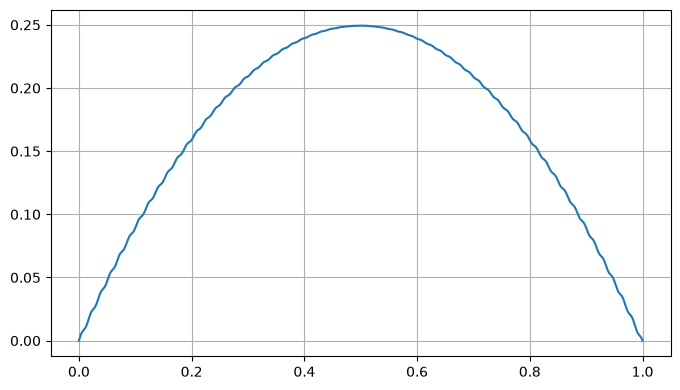

In [4]:
x = np.linspace(0, 1, 10000)
epsilon = 0.017

plt.plot(x, exact_solution(x, epsilon))

## Local elliptic and parabolic correctors

On each patch $S_K$, the elliptic corrector satisfies
$$\int_{S_K}a^\varepsilon w'v'=-\int_{S_K}a^\varepsilon v',\qquad w|_{\partial S_K}=0.$$
The parabolic corrector starts from zero and backward Euler discretizes
$$ (\partial_t w,v)+\int_{S_K}a^\varepsilon w'v'=-\int_{S_K}a^\varepsilon v'.$$
We write $\theta=T/\varepsilon^2$. If `theta=None`, the code uses the heuristic $\theta=(\sqrt3/(2\pi))R$.

In [5]:
def solve_local_corrector(patch_left, patch_right, h, epsilon, kind, T=0.0, n_time_steps=1):
    n_elements = int(np.rint((patch_right - patch_left) / h))
    if not np.isclose(n_elements*h, patch_right - patch_left):
        raise ValueError("patch endpoints are not aligned with the fine grid")

    domain = mesh.create_interval(MPI.COMM_SELF, n_elements, [patch_left, patch_right])
    V = fem.functionspace(domain, ("Lagrange", 1))
    boundary_vertices = mesh.locate_entities_boundary(
        domain, 0, lambda x: np.full(x.shape[1], True)
    )
    boundary_dofs = fem.locate_dofs_topological(V, 0, boundary_vertices)
    zero_boundary = fem.dirichletbc(default_scalar_type(0), boundary_dofs, V)

    x = ufl.SpatialCoordinate(domain)[0]
    a = 1.0 / (2.0 + ufl.cos(2.0*np.pi*x/epsilon))
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)
    dx = ufl.dx(metadata={"quadrature_degree": 8})
    prefix = f"corrector_{kind}_{next(_solver_counter)}_"
    solver_options = {"ksp_type": "preonly", "pc_type": "lu"}

    if kind == "elliptic":
        lhs = a*trial.dx(0)*test.dx(0)*dx
        rhs = -a*test.dx(0)*dx
        problem = LinearProblem(lhs, rhs, bcs=[zero_boundary],
                                petsc_options_prefix=prefix, petsc_options=solver_options)
        solution = problem.solve()
        solution.x.scatter_forward()

    elif kind == "parabolic":
        previous = fem.Function(V)
        dt = default_scalar_type(T / n_time_steps)
        lhs = (trial*test + dt*a*trial.dx(0)*test.dx(0))*dx
        rhs = (previous*test - dt*a*test.dx(0))*dx
        problem = LinearProblem(lhs, rhs, bcs=[zero_boundary],
                                petsc_options_prefix=prefix, petsc_options=solver_options)
        for _ in range(n_time_steps):
            solution = problem.solve()
            solution.x.scatter_forward()
            previous.x.array[:] = solution.x.array
        solution = previous

    else:
        raise ValueError("kind must be 'elliptic' or 'parabolic'")

    coordinates = V.tabulate_dof_coordinates()[:, 0]
    order = np.argsort(coordinates)
    return coordinates[order], solution.x.array[order].copy()

def solve_patch(cell, NH, Nh, n_delta, epsilon, kind, theta=None):
    H, h, _ = mesh_sizes(NH, Nh)
    delta, R = oversampling_width(n_delta, h, epsilon)
    cell_left, cell_right, patch_left, patch_right = patch_geometry(
        cell, NH, h, n_delta
    )

    if kind == "parabolic":
        theta = THETA_CONSTANT*R if theta is None else float(theta)
        if theta <= 0:
            raise ValueError("theta must be positive")
        T = theta * epsilon**2
        n_time_steps = max(20, int(np.ceil(theta / MAX_DIMENSIONLESS_DT)))
    else:
        theta, T, n_time_steps = np.inf, 0.0, 1

    x_patch, w_patch = solve_local_corrector(
        patch_left, patch_right, h, epsilon, kind, T, n_time_steps
    )
    retained = (x_patch >= cell_left - 1e-12) & (x_patch <= cell_right + 1e-12)
    x_cell = x_patch[retained]
    w_cell = w_patch[retained]

    if len(x_cell) != Nh + 1 or not np.allclose(x_cell, np.linspace(cell_left, cell_right, Nh + 1)):
        raise RuntimeError("the retained coarse cell is not aligned with the fine grid")

    return {
        "x_patch": x_patch, "w_patch": w_patch,
        "x_cell": x_cell, "w_cell": w_cell,
        "cell_left": cell_left, "cell_right": cell_right,
        "patch_left": patch_left, "patch_right": patch_right,
        "H": H, "h": h, "delta": delta, "R": R,
        "theta": theta, "T": T, "n_time_steps": n_time_steps,
    }

## Precisely defined error quantities

For a local corrector on the retained cell $K$, we report
$$\|w-\chi^\varepsilon\|_{L^2(K)},\qquad |w-\chi^\varepsilon|_{H^1(K)}=\|(w-\chi^\varepsilon)'\|_{L^2(K)}.$$
For the reconstructed nonconforming solution, we report the global $L^2(0,1)$ norm, the broken $H^1$ seminorm
$$|u_h-u_H^{ms}|_{H^1(\mathcal{T}_H)}^2=\sum_{K\in\mathcal{T}_H}\|(u_h-u_H^{ms})'\|_{L^2(K)}^2,$$
and the interface jump seminorm
$$J_H(u_H^{ms})^2=\sum_{z\in\mathcal N_H^\circ}H^{-1}[u_H^{ms}]_z^2.$$

In [6]:
gauss_points, gauss_weights = leggauss(8)

def integrate_on_interval(function, left, right):
    xq = 0.5*(left + right) + 0.5*(right - left)*gauss_points
    return 0.5*(right - left)*np.dot(gauss_weights, function(xq))

def corrector_error_norms(patch, epsilon):
    """Return L2 norm and H1 seminorm of w-chi^epsilon on the retained cell."""
    x = patch["x_cell"]
    w = patch["w_cell"]
    L2_squared = 0.0
    H1_seminorm_squared = 0.0

    for element in range(len(x) - 1):
        left, right = x[element], x[element + 1]
        length = right - left
        slope = (w[element + 1] - w[element]) / length

        def value_error_squared(xq):
            local_coordinate = (xq - left) / length
            wq = (1.0 - local_coordinate)*w[element] + local_coordinate*w[element + 1]
            return (wq - periodic_corrector(xq, epsilon))**2

        L2_squared += integrate_on_interval(value_error_squared, left, right)
        H1_seminorm_squared += integrate_on_interval(
            lambda xq: (slope - periodic_corrector_derivative(xq, epsilon))**2,
            left, right,
        )

    return np.sqrt(L2_squared), np.sqrt(H1_seminorm_squared)

## Fine reference solution and Petrov-Galerkin MsFEM assembly

In [7]:
def fine_reference_solution(NH, Nh, epsilon):
    """P1 FEM reference on the global fine grid, with f=1."""
    _, h, N_fine = mesh_sizes(NH, Nh)
    x = np.linspace(0.0, 1.0, N_fine + 1)
    midpoints = 0.5*(x[:-1] + x[1:])
    xq = midpoints[:, None] + 0.5*h*gauss_points[None, :]
    integral_a = 0.5*h*np.sum(gauss_weights[None, :]*coefficient(xq, epsilon), axis=1)
    element_stiffness = integral_a / h**2

    diagonal = element_stiffness[:-1] + element_stiffness[1:]
    off_diagonal = -element_stiffness[1:-1]
    stiffness_matrix = diags(
        [off_diagonal, diagonal, off_diagonal], [-1, 0, 1], format="csc"
    )
    load_vector = np.full(N_fine - 1, h)

    u = np.zeros(N_fine + 1)
    u[1:-1] = spsolve(stiffness_matrix, load_vector)
    return x, u

def corrected_coefficient_on_cell(patch, epsilon):
    """Cell average of a^epsilon(1+w')."""
    x = patch["x_cell"]
    w = patch["w_cell"]
    integral = 0.0
    for element in range(len(x) - 1):
        slope = (w[element + 1] - w[element]) / (x[element + 1] - x[element])
        integral += integrate_on_interval(
            lambda xq: coefficient(xq, epsilon)*(1.0 + slope),
            x[element], x[element + 1],
        )
    return integral / patch["H"]

def build_msfem(NH, Nh, n_delta, epsilon, kind, theta=None):
    """Assemble the Strategy-2 Petrov-Galerkin system."""
    H, _, _ = mesh_sizes(NH, Nh)
    matrix = np.zeros((NH + 1, NH + 1))
    load = np.zeros(NH + 1)
    local_template = np.array([[1.0, -1.0], [-1.0, 1.0]])
    patches = []

    for cell in range(NH):
        patch = solve_patch(cell, NH, Nh, n_delta, epsilon, kind, theta)
        patches.append(patch)
        corrected_coefficient = corrected_coefficient_on_cell(patch, epsilon)
        dofs = np.array([cell, cell + 1])
        matrix[np.ix_(dofs, dofs)] += corrected_coefficient/H * local_template
        load[dofs] += 0.5*H

    coarse_solution = np.zeros(NH + 1)
    coarse_solution[1:-1] = np.linalg.solve(matrix[1:-1, 1:-1], load[1:-1])
    return coarse_solution, patches

def reconstruct_solution(coarse_solution, patches):
    """Return one reconstructed P1 array per coarse cell."""
    pieces = []
    for cell, patch in enumerate(patches):
        x = patch["x_cell"]
        H = patch["H"]
        coarse_slope = (coarse_solution[cell + 1] - coarse_solution[cell]) / H
        coarse_linear = coarse_solution[cell] + coarse_slope*(x - patch["cell_left"])
        reconstructed = coarse_linear + coarse_slope*patch["w_cell"]
        pieces.append((x.copy(), reconstructed))
    return pieces

def reconstructed_solution_error_norms(pieces, x_reference, u_reference, NH, Nh):
    """Return global L2 norm, broken H1 seminorm, and interface jump seminorm."""
    H, _, _ = mesh_sizes(NH, Nh)
    L2_squared = 0.0
    broken_H1_seminorm_squared = 0.0

    for cell, (x, u) in enumerate(pieces):
        start = cell * Nh
        reference_x = x_reference[start:start + Nh + 1]
        reference_u = u_reference[start:start + Nh + 1]
        if not np.allclose(x, reference_x):
            raise RuntimeError("reconstruction and reference grids are not aligned")

        difference = u - reference_u
        lengths = np.diff(x)
        L2_squared += np.sum(
            lengths*(difference[:-1]**2 + difference[:-1]*difference[1:] + difference[1:]**2)/3.0
        )
        derivative_difference = np.diff(difference) / lengths
        broken_H1_seminorm_squared += np.sum(lengths*derivative_difference**2)

    jumps = np.array([pieces[cell][1][-1] - pieces[cell + 1][1][0]
                      for cell in range(NH - 1)])
    jump_seminorm = np.sqrt(np.sum(jumps**2) / H)
    return {
        "L2_norm": np.sqrt(L2_squared),
        "broken_H1_seminorm": np.sqrt(broken_H1_seminorm_squared),
        "jump_seminorm": jump_seminorm,
        "jumps": jumps,
    }

## Fine-reference discretization error

Because $\varepsilon$ need not fit an integer number of periods in $(0,1)$, the integration constant in the exact solution is determined from $u^\varepsilon(1)=0$. The following cell reports the $L^2(0,1)$ norm and $H^1(0,1)$ seminorm of the fine P1 reference error.

In [8]:
def reference_solution_error_norms(x_reference, u_reference, epsilon):
    """Return ||u^epsilon-u_h||_L2 and |u^epsilon-u_h|_H1."""
    L2_squared = 0.0
    H1_seminorm_squared = 0.0

    for element in range(len(x_reference) - 1):
        left = x_reference[element]
        right = x_reference[element + 1]
        length = right - left
        nodal_left = u_reference[element]
        nodal_right = u_reference[element + 1]
        reference_derivative = (nodal_right - nodal_left) / length

        def value_error_squared(xq):
            local_coordinate = (xq - left) / length
            reference_value = ((1.0 - local_coordinate)*nodal_left
                               + local_coordinate*nodal_right)
            return (exact_solution(xq, epsilon) - reference_value)**2

        L2_squared += integrate_on_interval(value_error_squared, left, right)
        H1_seminorm_squared += integrate_on_interval(
            lambda xq: (exact_solution_derivative(xq, epsilon)
                        - reference_derivative)**2,
            left, right,
        )

    return np.sqrt(L2_squared), np.sqrt(H1_seminorm_squared)

x_reference, u_reference = fine_reference_solution(NH, Nh, epsilon)
reference_L2_error, reference_H1_error = reference_solution_error_norms(
    x_reference, u_reference, epsilon
)
print(f"||u^epsilon-u_h||_L2(0,1) = {reference_L2_error:.6e}")
print(f"|u^epsilon-u_h|_H1(0,1) = {reference_H1_error:.6e}")

||u^epsilon-u_h||_L2(0,1) = 6.664931e-05
|u^epsilon-u_h|_H1(0,1) = 1.065582e-02


## One local corrected basis

The first plot shows the corrected right basis on the retained coarse cell. The second plot shows the corrector on the full patch and marks the exact zero Dirichlet endpoints.

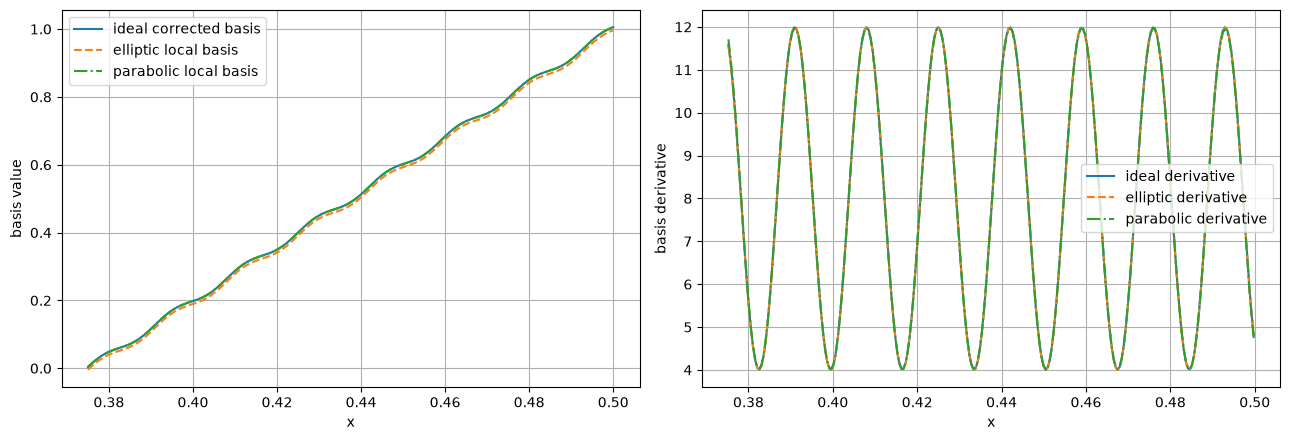

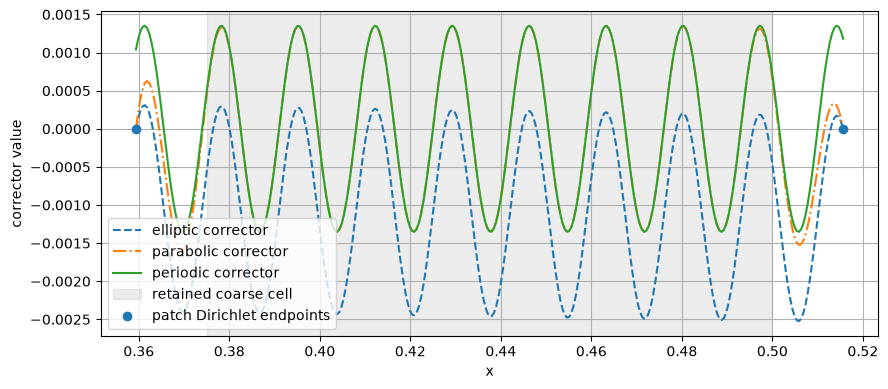

elliptic  : L2 norm error=3.930048e-04, H1 seminorm error=6.572301e-03
            patch boundary values=[0. 0.]
parabolic : L2 norm error=4.547993e-06, H1 seminorm error=6.653658e-03
            patch boundary values=[0. 0.]


In [9]:
cell_example = NH//2 - 1
elliptic_patch = solve_patch(cell_example, NH, Nh, n_delta, epsilon, "elliptic")
parabolic_patch = solve_patch(cell_example, NH, Nh, n_delta, epsilon, "parabolic")

x_cell = elliptic_patch["x_cell"]
cell_left = elliptic_patch["cell_left"]
coarse_right_basis = (x_cell - cell_left) / H
ideal_basis = coarse_right_basis + periodic_corrector(x_cell, epsilon)/H
elliptic_basis = coarse_right_basis + elliptic_patch["w_cell"]/H
parabolic_basis = coarse_right_basis + parabolic_patch["w_cell"]/H
midpoints = 0.5*(x_cell[:-1] + x_cell[1:])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(x_cell, ideal_basis, label='ideal corrected basis')
axes[0].plot(x_cell, elliptic_basis, '--', label='elliptic local basis')
axes[0].plot(x_cell, parabolic_basis, '-.', label='parabolic local basis')
axes[0].set_xlabel('x'); axes[0].set_ylabel('basis value'); axes[0].legend()
axes[1].plot(midpoints, np.diff(ideal_basis)/h, label='ideal derivative')
axes[1].plot(midpoints, np.diff(elliptic_basis)/h, '--', label='elliptic derivative')
axes[1].plot(midpoints, np.diff(parabolic_basis)/h, '-.', label='parabolic derivative')
axes[1].set_xlabel('x'); axes[1].set_ylabel('basis derivative'); axes[1].legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4))
plt.plot(elliptic_patch['x_patch'], elliptic_patch['w_patch'], '--', label='elliptic corrector')
plt.plot(parabolic_patch['x_patch'], parabolic_patch['w_patch'], '-.', label='parabolic corrector')
plt.plot(elliptic_patch['x_patch'], periodic_corrector(elliptic_patch['x_patch'], epsilon),
         label='periodic corrector')
plt.axvspan(elliptic_patch['cell_left'], elliptic_patch['cell_right'],
            color='grey', alpha=0.15, label='retained coarse cell')
plt.scatter([elliptic_patch['patch_left'], elliptic_patch['patch_right']], [0.0, 0.0],
            color='C0', zorder=5, label='patch Dirichlet endpoints')
plt.xlabel('x'); plt.ylabel('corrector value'); plt.legend(); plt.tight_layout(); plt.show()

for name, patch in [('elliptic', elliptic_patch), ('parabolic', parabolic_patch)]:
    L2_error, H1_error = corrector_error_norms(patch, epsilon)
    print(f"{name:10s}: L2 norm error={L2_error:.6e}, H1 seminorm error={H1_error:.6e}")
    print(f"{'':10s}  patch boundary values={patch['w_patch'][[0, -1]]}")

## Oversampling-width sweep

Here $N_H$, $N_h$, $H$, $h$, and $\varepsilon$ remain fixed. We vary only the integer number of oversampling layers $n_\delta$, hence $\delta=n_\delta h$ and $R=\delta/\varepsilon$.

In [10]:
n_delta_values = np.linspace(1, int(2*H/h), 25, dtype=int)
R_values = n_delta_values*h/epsilon
delta_results = {"elliptic": [], "parabolic": []}
probe_cell = NH//2 - 1

for kind in delta_results:
    for layers in n_delta_values:
        coarse_solution, patches = build_msfem(NH, Nh, int(layers), epsilon, kind)
        corrector_L2, corrector_H1 = corrector_error_norms(patches[probe_cell], epsilon)
        pieces = reconstruct_solution(coarse_solution, patches)
        solution_errors = reconstructed_solution_error_norms(
            pieces, x_reference, u_reference, NH, Nh
        )
        delta_results[kind].append({
            "corrector_L2_norm": corrector_L2,
            "corrector_H1_seminorm": corrector_H1,
            **solution_errors,
        })

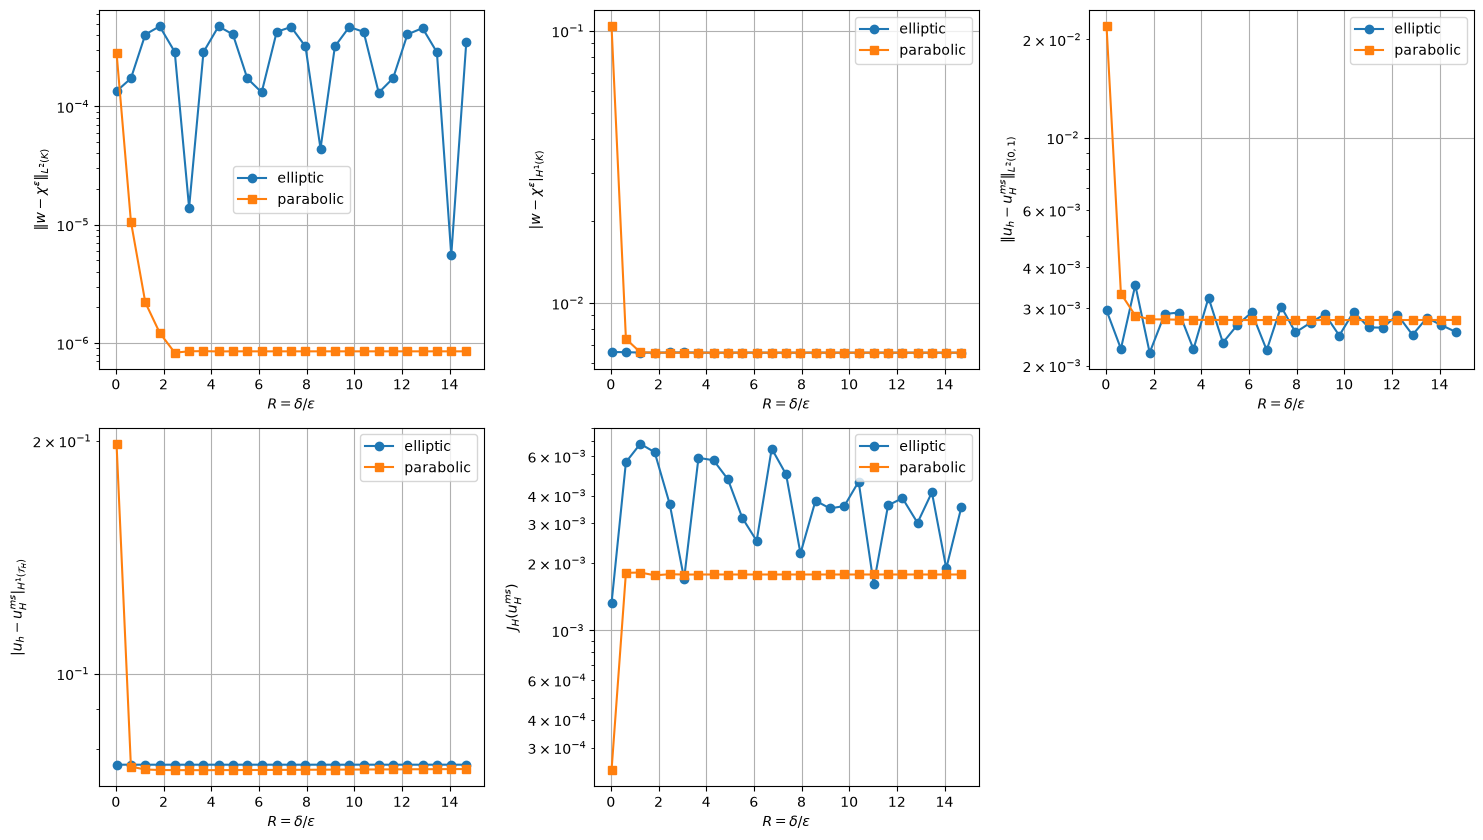

In [11]:
quantities = [
    ("corrector_L2_norm", r'$\|w-\chi^\varepsilon\|_{L^2(K)}$'),
    ("corrector_H1_seminorm", r'$|w-\chi^\varepsilon|_{H^1(K)}$'),
    ("L2_norm", r'$\|u_h-u_H^{ms}\|_{L^2(0,1)}$'),
    ("broken_H1_seminorm", r'$|u_h-u_H^{ms}|_{H^1(\mathcal{T}_H)}$'),
    ("jump_seminorm", r'$J_H(u_H^{ms})$'),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for axis, (key, ylabel) in zip(axes.flat, quantities):
    for kind, style in [("elliptic", 'o-'), ("parabolic", 's-')]:
        axis.semilogy(R_values, [row[key] for row in delta_results[kind]], style, label=kind)
    axis.set_xlabel(r'$R=\delta/\varepsilon$')
    axis.set_ylabel(ylabel)
    axis.legend()
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

## Final-time sweep

This experiment fixes $N_H$, $N_h$, $\varepsilon$, and $n_\delta$, and varies only the dimensionless final time $\theta=T/\varepsilon^2$.

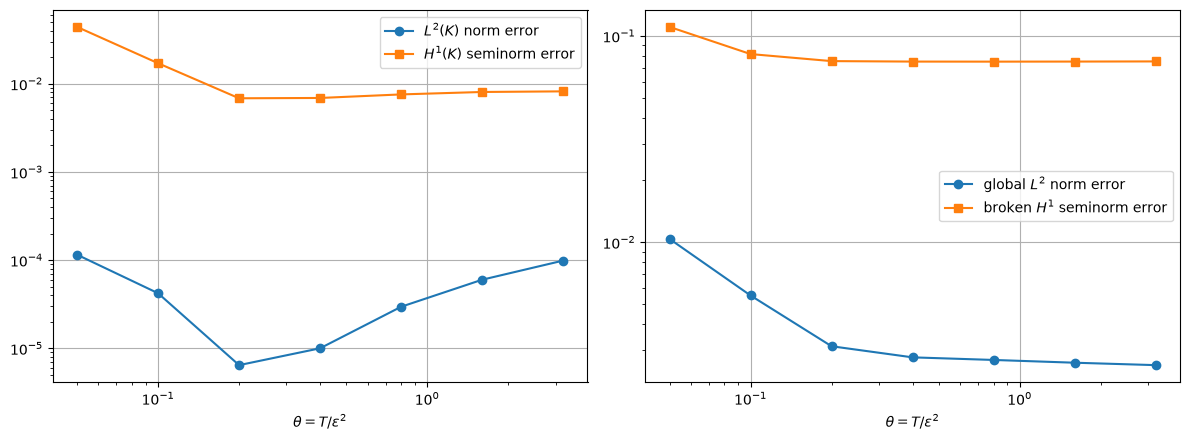

In [12]:
theta_values = np.array([0.05, 0.10, 0.20, 0.40, 0.80, 1.60, 3.20])
time_results = []

for theta in theta_values:
    coarse_solution, patches = build_msfem(
        NH, Nh, n_delta, epsilon, "parabolic", theta=theta
    )
    corrector_L2, corrector_H1 = corrector_error_norms(patches[probe_cell], epsilon)
    pieces = reconstruct_solution(coarse_solution, patches)
    solution_errors = reconstructed_solution_error_norms(
        pieces, x_reference, u_reference, NH, Nh
    )
    time_results.append({
        "corrector_L2_norm": corrector_L2,
        "corrector_H1_seminorm": corrector_H1,
        **solution_errors,
    })

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].loglog(theta_values, [row['corrector_L2_norm'] for row in time_results],
               'o-', label=r'$L^2(K)$ norm error')
axes[0].loglog(theta_values, [row['corrector_H1_seminorm'] for row in time_results],
               's-', label=r'$H^1(K)$ seminorm error')
axes[1].loglog(theta_values, [row['L2_norm'] for row in time_results],
               'o-', label=r'global $L^2$ norm error')
axes[1].loglog(theta_values, [row['broken_H1_seminorm'] for row in time_results],
               's-', label=r'broken $H^1$ seminorm error')
for axis in axes:
    axis.set_xlabel(r'$\theta=T/\varepsilon^2$')
    axis.legend()
plt.tight_layout(); plt.show()

## Coarse-mesh sweep

For every $N_H$, we again define $H=1/N_H$ and $h=H/N_h$. Thus nestedness is automatic. The integer $n_\delta$ is chosen so that $R=\delta/\varepsilon$ stays close to a prescribed target. Each multiscale solution is compared with a fine P1 reference computed on its own corresponding fine grid.

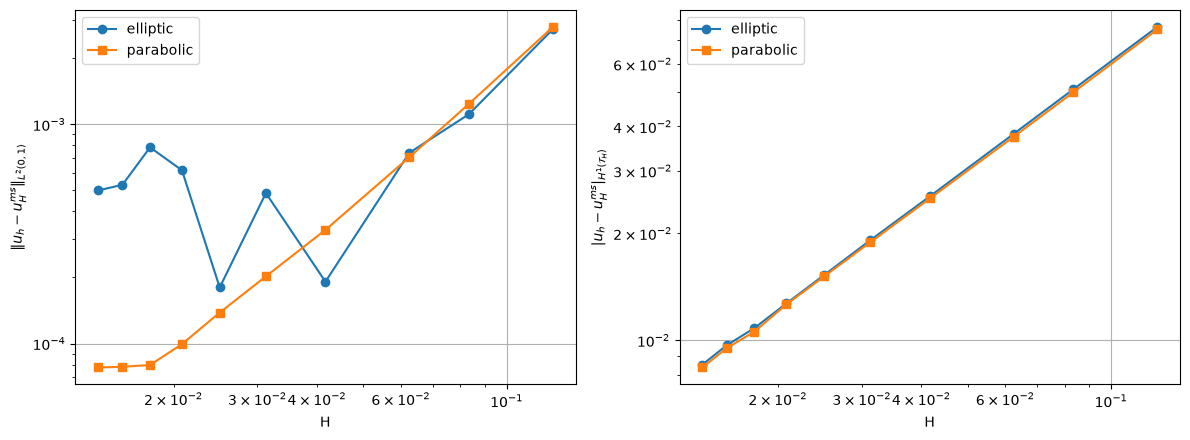

H values: [0.125      0.08333333 0.0625     0.04166667 0.03125    0.025
 0.02083333 0.01785714 0.015625   0.01388889]
h values: [0.00048828 0.00048733 0.00048828 0.0004902  0.00048828 0.0004902
 0.0004845  0.00048263 0.00048828 0.00049603]
actual R values: [2.01056985 2.00665061 2.01056985 1.98961938 2.01056985 1.98961938
 1.99498404 1.9872814  2.01056985 2.01330532]


In [13]:
h_for_H_sweep = 1/(256*8)
NH_values = np.array([8, 12, 16, 24, 32, 40, 48, 56, 64, 72])
Nh_for_H_sweep = np.array(np.rint(1/(NH_values*h_for_H_sweep)), dtype=int)

target_R = 2
H_results = {"elliptic": [], "parabolic": []}
actual_R_values = []

for i, NH_current in enumerate(NH_values):
    H_current, h_current, _ = mesh_sizes(int(NH_current), Nh_for_H_sweep[i])
    n_delta_current = max(1, int(np.rint(target_R*epsilon/h_current)))
    _, R_current = oversampling_width(n_delta_current, h_current, epsilon)
    actual_R_values.append(R_current)
    x_ref_current, u_ref_current = fine_reference_solution(
        int(NH_current), Nh_for_H_sweep[i], epsilon
    )

    for kind in H_results:
        coarse_solution, patches = build_msfem(
            int(NH_current), Nh_for_H_sweep[i], n_delta_current, epsilon, kind
        )
        pieces = reconstruct_solution(coarse_solution, patches)
        errors = reconstructed_solution_error_norms(
            pieces, x_ref_current, u_ref_current, int(NH_current), Nh_for_H_sweep[i]
        )
        H_results[kind].append(errors)

H_values = 1.0 / NH_values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for kind, style in [("elliptic", 'o-'), ("parabolic", 's-')]:
    axes[0].loglog(H_values, [row['L2_norm'] for row in H_results[kind]], style, label=kind)
    axes[1].loglog(H_values, [row['broken_H1_seminorm'] for row in H_results[kind]], style, label=kind)
axes[0].set_xlabel('H'); axes[0].set_ylabel(r'$\|u_h-u_H^{ms}\|_{L^2(0,1)}$')
axes[1].set_xlabel('H'); axes[1].set_ylabel(r'$|u_h-u_H^{ms}|_{H^1(\mathcal{T}_H)}$')
for axis in axes:
    axis.legend()
plt.tight_layout(); plt.show()

print('H values:', H_values)
print('h values:', H_values/Nh_for_H_sweep)
print('actual R values:', np.asarray(actual_R_values))